# Session 5b : Data visualisation

#### Master TIDE 2026-2027

1. **Préparation des données**
2. **Analyse en composantes principales**
3. **Production d'un scatter plot avec plotly.express**
4. **Application de l'algorithme t-SNE**

&copy; 2026 Francis Wolinski

### Objectifs du notebook

L'objectif de ce notebook est de mettre en oeuvre des **algorithmes de réduction de dimension** pour visualiser en 2D des données numériques multi-dimensionnelles.

Le jeu de données vient des Nations Unies (UNCTAD) sur les facteurs de développement du e-commerce par pays :
- \% d'individus utilisant Internet, source International Telecommunication Union (ITU)
- \% d'individus avec un compte bancaire (15+), source World Bank
- nombre de serveurs Internet sécurisés par 1 million de personnes, source World Bank
- score de fiabilité postale, source Universal Postal Union (UPU)

Source : https://unctad.org/system/files/official-document/tn_unctad_ict4d17_en.pdf

### 1. Préparation des données

In [1]:
# imports
import numpy as np
import pandas as pd

- Charger le jeu de données de e-commerce "./data/e-commerce_index_2020.txt"
- Charger également la page "https://www.geonames.org/countries/" en sélectionnant le DataFrame avec ~250 lignes, ou bien le fichier "./data/GeoNames.html". Attention aux *NA* !
- Effectuer une jointure *inner* entre le dataset e-commerce et les pays. Le résultat a combien de lignes ?
- Effectuer une jointure *left* entre le dataset e-commerce et les pays et sélectionner les lignes pour lesquelles la colonne "Country" est "NaN".
- Utiliser le dictionnaire *mapping* pour transformer la colonne "Economy" du dataset e-commerce et refaites la jointure. Le résultat a combien de lignes ?

In [4]:
ecom = pd.read_csv("./data/e-commerce_index_2020.txt", sep=";", usecols=[1, 2, 3, 4, 5])
ecom.head()

,Economy,Share of individuals using the Internet (2019 or latest),"Share of individuals with an account (15+, 2017)","Secure Internet servers (normalized, 2019)",UPU postal reliability score (2019 or latest)
0,Switzerland,97,98,92,97
1,Netherlands,96,100,94,93
2,Denmark,97,100,100,81
3,Singapore,89,98,94,97
4,United Kingdom,96,96,84,98


In [7]:
ecom.shape

(152, 5)

In [5]:
tables = pd.read_html("https://www.geonames.org/countries")
[df.shape for df in tables]

[(250, 9)]

In [6]:
countries = tables[0]
countries.head()

,ISO-3166 alpha2 ▲,ISO-3166 alpha3,ISO-3166 numeric,fips,Country,Capital,Area in km²,Population,Continent
0,AD,AND,20,AN,Andorra,Andorra la Vella,468.0,82904,EU
1,AE,ARE,784,AE,United Arab Emirates,Abu Dhabi,82880.0,11513149,AS
2,AF,AFG,4,AF,Afghanistan,Kabul,647500.0,43844111,AS
3,AG,ATG,28,AC,Antigua and Barbuda,St. John's,443.0,94209,NaN
4,AI,AIA,660,AV,Anguilla,The Valley,102.0,13254,NaN


In [8]:
ecom2 = pd.merge(ecom, countries, left_on="Economy", right_on="Country", how="inner")
ecom2.shape

(135, 14)

In [11]:
ecom.loc[ecom["Economy"].str.startswith("Bolivia")]

,Economy,Share of individuals using the Internet (2019 or latest),"Share of individuals with an account (15+, 2017)","Secure Internet servers (normalized, 2019)",UPU postal reliability score (2019 or latest)
102,Bolivia (Plurinational State of),47,54,43,12


In [14]:
countries.loc[countries["Country"].str.startswith("Bolivia")]

,ISO-3166 alpha2 ▲,ISO-3166 alpha3,ISO-3166 numeric,fips,Country,Capital,Area in km²,Population,Continent
28,BO,BOL,68,BL,Bolivia,Sucre,1098580.0,12581843,SA


In [15]:
# mapping entre les noms des pays

mapping = {
    'Bolivia (Plurinational State of)': 'Bolivia',
    'China, Hong Kong SAR': 'Hong Kong',
    'Congo': 'Congo Republic',
    'Cōte d\'Ivoire': 'Ivory Coast',
    'Dem. Rep. of the Congo': 'DR Congo',
    'Iran (Islamic Republic of)': 'Iran',
    'Korea, Republic of': 'North Korea',
    'Lao People\'s Dem. Rep.': 'Laos',
    'Netherlands': 'The Netherlands',
    'Republic of Moldova': 'Moldova',
    'Russian Federation': 'Russia',
    'Syrian Arab Republic': 'Syria',
    'United Republic of Tanzania': 'Tanzania',
    'United States of America': 'United States',
    'Venezuela (Bolivarian Rep. of)': 'Venezuela',
    'Viet Nam': 'Vietnam',
    'Yemen, Arab Republic': 'Yemen',
}

len(mapping)

17

In [17]:
ecom["Economy"].map(mapping)

0                  NaN
1      The Netherlands
2                  NaN
3                  NaN
4                  NaN
            ...       
147           DR Congo
148                NaN
149                NaN
150                NaN
151                NaN
Name: Economy, Length: 152, dtype: str

In [21]:
ecom["Economy"] = ecom["Economy"].apply(lambda x: mapping.get(x, x))

In [22]:
ecom2 = pd.merge(ecom, countries, left_on="Economy", right_on="Country", how="inner")
ecom2.shape

(150, 14)

In [24]:
join = pd.merge(ecom, countries, left_on="Economy", right_on="Country", how="left")
join.loc[join["Country"].isna()]

,Economy,Share of individuals using the Internet (2019 or latest),"Share of individuals with an account (15+, 2017)","Secure Internet servers (normalized, 2019)",UPU postal reliability score (2019 or latest),ISO-3166 alpha2 ▲,ISO-3166 alpha3,ISO-3166 numeric,fips,Country,Capital,Area in km²,Population,Continent
146,Congo Republic,9,26,17,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
147,DR Congo,9,26,11,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 2. Analyse en composantes principales

> PCA is used to decompose a multivariate dataset in a set of successive orthogonal components that explain a maximum amount of the variance.
> Voir également le lien : https://yotta-conseil.fr/Developing_an_Intuition_on_PCA.html
  
* Sélectionner les données des 4 facteurs de e-commerce.
* Normaliser ces données avec un StandardScaler (dans `sklearn.preprocessing`) avec la méthode `fit_transform()`. On obtient une matrice à 4 colonnes.
* Instancier un PCA (dans `sklearn.decomposition`) avec le paramètre `n_components=2`.
* Appliquer la méthode `fit_transform()` aux données standardisées. On obtient une matrice à 2 colonnes.
* Obtenir les composantes de l'ACP (`pca.components_`) ainsi que le % de variance expliquée par composante (`pca.explained_variance_ratio_`)
* Fusionner les 2 colonnes obtenues transformées en Series avec les colonnes "Population", "Continent" et "Country" des pays avec la fonction `concat()`. On obtient un DataFrame à cinq colonnes.
* Au moment de la fusion des résultats, il faudra peut-être prendre l'opposé de la première colonne numérique, afin d'obtenir un graphique standard avec, à droite, les pays dont les facteurs de e-commerce sont les plus élevés.


In [27]:
data = ecom2.iloc[:, 1:5]
data

,Share of individuals using the Internet (2019 or latest),"Share of individuals with an account (15+, 2017)","Secure Internet servers (normalized, 2019)",UPU postal reliability score (2019 or latest)
0,97,98,92,97
1,96,100,94,93
2,97,100,100,81
3,89,98,94,97
4,96,96,84,98
...,...,...,...,...
145,9,20,16,13
146,8,22,18,0
147,3,7,20,3
148,7,22,0,0


In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

pipeline = Pipeline([("std", StandardScaler()), ("pca", PCA(n_components=2))])
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('std', ...), ('pca', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd

In [29]:
result = pipeline.fit_transform(data)
result

array([[ 2.86745145e+00,  1.84392126e-01],
       [ 2.87701079e+00,  5.09072466e-02],
       [ 2.86485099e+00, -3.17821969e-01],
       [ 2.76791293e+00,  2.49225441e-01],
       [ 2.65040389e+00,  3.04583828e-01],
       [ 2.69008030e+00,  7.06308739e-02],
       [ 2.70088525e+00,  5.37629594e-02],
       [ 2.66343049e+00,  3.36222911e-01],
       [ 2.62673696e+00, -2.45010193e-02],
       [ 2.56684907e+00,  1.69572536e-01],
       [ 2.53394915e+00,  1.78159360e-01],
       [ 2.54419886e+00,  1.45979512e-01],
       [ 2.50134087e+00,  4.53935056e-02],
       [ 2.54533331e+00, -7.79299601e-02],
       [ 2.52916985e+00, -1.13990164e-01],
       [ 2.48348177e+00,  1.89868521e-01],
       [ 2.41182875e+00,  3.01354520e-01],
       [ 2.30838258e+00,  4.89164793e-01],
       [ 2.35288185e+00,  8.81490049e-02],
       [ 2.31417743e+00,  2.97475943e-01],
       [ 2.23420951e+00, -1.30266412e-01],
       [ 2.16100158e+00,  2.82180592e-01],
       [ 2.07809945e+00,  5.55542884e-01],
       [ 2.

In [35]:
result[:, 0]

array([ 2.86745145,  2.87701079,  2.86485099,  2.76791293,  2.65040389,
        2.6900803 ,  2.70088525,  2.66343049,  2.62673696,  2.56684907,
        2.53394915,  2.54419886,  2.50134087,  2.54533331,  2.52916985,
        2.48348177,  2.41182875,  2.30838258,  2.35288185,  2.31417743,
        2.23420951,  2.16100158,  2.07809945,  2.11803244,  1.98513404,
        2.0073309 ,  1.93225749,  1.89231928,  1.85935103,  1.76985261,
        1.75145198,  2.00908669,  1.61309383,  1.81790994,  1.60126227,
        1.86780289,  1.59352036,  1.65546746,  1.70882578,  1.61907882,
        1.50091826,  1.30783249,  1.35850001,  1.30070667,  1.31337907,
        1.34416354,  1.10864006,  1.41886257,  1.03414218,  1.07925915,
        1.01211544,  1.0326776 ,  0.92667504,  0.93274008,  0.89203685,
        0.92844587,  0.97297209,  0.9651715 ,  1.0370261 ,  0.87861206,
        0.80954745,  0.63177477,  0.30861465,  0.17356762,  0.14434808,
        0.48847199,  0.14437783,  0.13794761,  0.30101862,  0.27

In [31]:
pipeline["pca"].components_

array([[ 0.50748943,  0.50687652,  0.52745581,  0.4553252 ],
       [-0.28286951, -0.32291315, -0.18130999,  0.88478168]])

In [32]:
pipeline["pca"].explained_variance_ratio_

array([0.79543079, 0.10822089])

In [39]:
dataviz = pd.concat([pd.Series(result[:, 0], name="x"),
                    pd.Series(result[:, 1], name="y"),
                    ecom2["Country"],
                    ecom2["Population"],
                    ecom2["Continent"]], axis=1)
dataviz.head()

,x,y,Country,Population,Continent
0,2.867451,0.184392,Switzerland,9092436,EU
1,2.877011,0.050907,The Netherlands,18087633,EU
2,2.864851,-0.317822,Denmark,6009169,EU
3,2.767913,0.249225,Singapore,6111175,AS
4,2.650404,0.304584,United Kingdom,69487000,EU


### 3. Production d'un scatter plot avec plotly.express

In [40]:
# import
import plotly.express as px

Il peut être nécessaire de fixer le moteur de rendu de **plotly** avec l'instruction suivante en en choisissant un parmi la liste fournie.

In [41]:
# renderers
import plotly.io as pio
print(pio.renderers)
pio.renderers.default = 'jupyterlab'

Renderers configuration
-----------------------
    Default renderer: 'plotly_mimetype'
    Available renderers:
        ['plotly_mimetype', 'jupyterlab', 'nteract', 'vscode',
         'notebook', 'notebook_connected', 'kaggle', 'azure', 'colab',
         'cocalc', 'databricks', 'json', 'png', 'jpeg', 'jpg', 'svg',
         'pdf', 'browser', 'firefox', 'chrome', 'chromium', 'iframe',
         'iframe_connected', 'sphinx_gallery', 'sphinx_gallery_png']



Les graphiques sont produits avec une barre d'outils offrant différentes fonctions (snapshot, zoom, sélection, recentrage...).

Il est possible de masquer ce menu avec l'instruction :
```python
fig.show(config={'displayModeBar': False})
```

Les options de configuration sont explicitée dans cette page : https://plotly.com/python/configuration-options/

#### Correspondances matplotlib / seaborn / plotly (extrait)

matplotlib|seaborn|plotly
-|-|-
bar|barplot|bar
pie|barplot|pie
-|stripplot|strip
scatter|scatterplot|scatter
boxplot|boxplot|box
violinplot|violinplot|violin
hist|displot|histogram
-|heatmap|imshow
-|pairplot|scatter_matrix
-|joinplot|density_heatmap
-|FacetGrid|paramètres "facet_row" et "facet_col"

Compléter le code ci-dessous pour produire un graphique avec **plotly.express**.

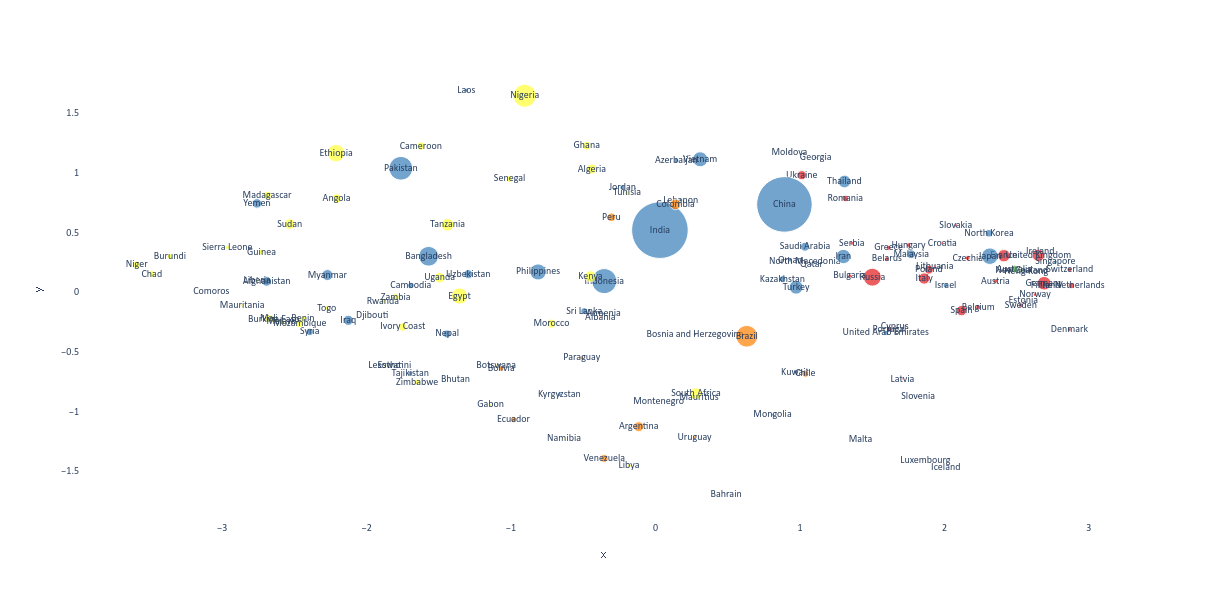

In [42]:
# à vous de jouer
fig = px.scatter(data_frame=dataviz,
           x="x",
           y="y",
           color="Continent",
           size="Population",
           text="Country",
           color_discrete_sequence = px.colors.qualitative.Set1,
           size_max=40)

fig.update_layout(font_size=10,
                  font_family="Calibri",
                  showlegend=False,
                  height=600,
                  plot_bgcolor="white")

### 4. Application de l'algorithme t-SNE

> t-SNE (TSNE) converts affinities of data points to probabilities. The affinities in the original space are represented by Gaussian joint probabilities and the affinities in the embedded space are represented by Student’s t-distributions.

* A l'étape 2, instancier un `TSNE` (dans `sklearn.manifold`) avec le paramètre `perplexity=8` (lié au nombre de voisins utilisés par l'algorithme), ainsi qu'un `random_state` pour la reproductibilité des résultats.
* Remplacez ensuite le PCA par un TSNE. La suite du code reste valable.